# Method 6: GRU sequence model
A recurrent network reads a player's matches in order and, after every match, outputs the full-season per-90 profile.

- **Input per match:** the running per-90 as z-scores against the training distribution at that many minutes, the single match's per-90 as z-scores, `log(match minutes)`, `log(running minutes)` and the step number / 10.
- **Network:** linear layer, one GRU layer (96 units), dropout 0.2, a linear head plus a linear skip from the running z-scores (so it starts as a linear model). Trained with AdamW, the loss is the weighted squared error of the full-season z-score (so every stat counts equally, like the nrmse metric).
- **Training rows:** every prefix of every training season is a training example (the network is causal, so each step is one prefix). Early stopping on 10% of the training players. One model per gender and group.
- It uses the same training data as the ridge; only the model class differs.

**Setup shared by every method.** One model per gender and position group, trained on every per-game prefix (the player's first k matches, up to 750 minutes) of the 900+ minute player-seasons, each with its full-season per-90 as the target. The same fitted model handles any number of minutes. Rates, ratios and percents are never estimated: they are rebuilt from the estimated per-90 volumes.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)
print({k: getattr(tm, k) for k in ["GRU_HIDDEN", "GRU_DROPOUT", "GRU_LR", "GRU_WD", "GRU_BATCH", "GRU_MAX_EPOCHS", "GRU_PATIENCE"]})

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74
{'GRU_HIDDEN': 96, 'GRU_DROPOUT': 0.2, 'GRU_LR': 0.002, 'GRU_WD': 0.01, 'GRU_BATCH': 128, 'GRU_MAX_EPOCHS': 60, 'GRU_PATIENCE': 6}


## 1. Results across all 14 gender / position-group sets

**How to read the numbers.** `nrmse` is the RMSE of the estimate against the player's true full-season
per-90, divided by the standard deviation of that true value. 0 is perfect; 1 means no better than guessing
the group average. Every table shows the **median over stats** (and over groups/genders unless stated).
The three columns / x positions are **minutes bins** of the sample the estimate was made from: 250 = 0-375 minutes,
500 = 375-625, 750 = 625-750 (every per-game prefix of a held-out player is scored; each player-season counts once
per bin). Scores are out-of-fold: the 5 folds split players, so nobody is predicted by a model that saw them.

method,raw,ridge,ridge_kalman,gru
checkpoint,,,,
250,1.489,0.769,0.764,0.773
500,0.713,0.552,0.552,0.588
750,0.518,0.457,0.455,0.511


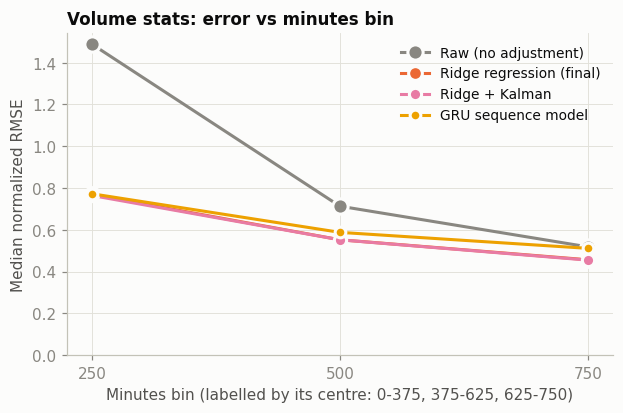

mean_diff  better  worse  sets
method       checkpoint                                
gru          250            0.5507       0      8    14
             500            0.5451       0     14    14
             750            0.5884       0     14    14
ridge_kalman 250           -0.0252      13      0    14
             500           -0.0011       8      1    14
             750           -0.0147       9      0    14

In [2]:
METHODS = ["raw", "ridge", "ridge_kalman", "gru"]
summary = nh.median_nrmse(V, METHODS)
display(summary.round(3))
nh.curve_plot(summary, METHODS, "Volume stats: error vs minutes bin")
plt.show()
display(nh.paired_summary(P, ["gru", "ridge_kalman"]).round(4))

Error reduction versus raw by position group:

checkpoint,250,500,750
group,,,
Attacking Midfielders,44.7,11.3,-4.9
Center Backs,50.3,21.6,9.6
Center Forwards,46.9,15.2,-1.9
Central Midfielders,45.9,16.7,3.6
GK,56.0,27.5,12.5
Outside Backs,48.5,17.8,5.0
Wingers,45.5,9.9,-11.7


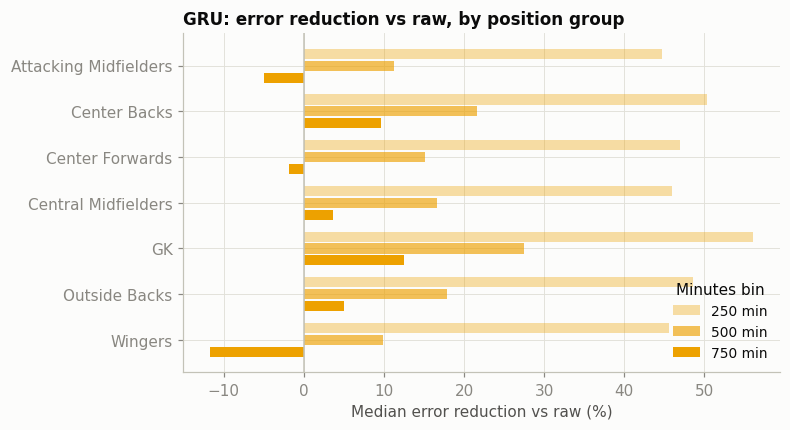

In [3]:
by_group = nh.improvement_by_group(V, "gru")
display(by_group.mul(100).round(1))
nh.group_bars(by_group, "gru", "GRU: error reduction vs raw, by position group")
plt.show()

### Rates rebuilt from the estimated volumes

In [4]:
display(nh.median_nrmse(R, METHODS).round(3).rename_axis("minutes bin"))
display(nh.missing_table(R, METHODS).round(4))

method,raw,ridge,ridge_kalman,gru
minutes bin,,,,
250,1.737,0.857,0.843,0.877
500,0.838,0.654,0.650,0.730
750,0.610,0.564,0.560,0.667


,n_truth_ok,n_est_missing,n_compared,est_missing_share
method,,,,
raw,17532604,1039980,16492624,0.0593
ridge,17532604,162703,17369901,0.0093
ridge_kalman,17532604,162126,17370478,0.0092
gru,17532604,168209,17364395,0.0096


## 2. Worked example: male Wingers (live run)

raw     median nrmse @250/500/750: [1.378, 0.627, 0.451]
ridge   median nrmse @250/500/750: [0.745, 0.519, 0.417]
gru     median nrmse @250/500/750: [0.75, 0.577, 0.507]


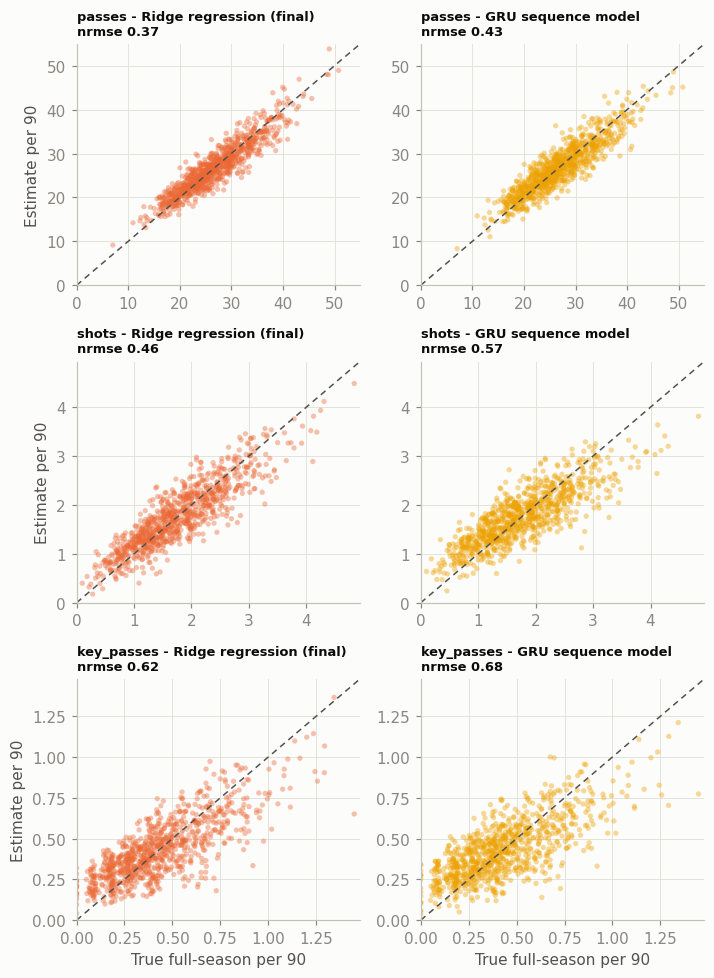

In [5]:
METHOD = "gru"
pool, stems, est = nh.demo_group("male", "Wingers", ["raw", "ridge", METHOD])
for m in ["raw", "ridge", METHOD]:
    print(f"{m:7s} median nrmse @250/500/750:",
          [round(float(nh.nrmse_per_stat(pool, est[m], b).median()), 3) for b in (250, 500, 750)])
fig = nh.scatter_grid(pool, est, ["passes", "shots", "key_passes"], 500, ["ridge", METHOD])
plt.show()

### Strengths and limits
- Can in principle learn order effects and nonlinear interactions between stats.
- With roughly 1,000 to 4,000 seasons per group it overfits: close to the ridge at the smallest minutes bin, clearly worse at 500 and 750.
- One architecture and one seed, not tuned; this is not a full verdict on sequence models.
- A simpler test of whether order matters (recent-form trend features in the ridge) found no gain, which fits the weak result here.